In [4]:
"""Retinal vessel segmentation: offline PyTorch training and exact sample-format CSV."""
from __future__ import annotations

import argparse
import csv
import json
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
from PIL import Image, ImageFilter
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader


@dataclass
class Config:
    data_dir: str = ""  # Empty: search Kaggle input and the current directory.
    output_dir: str = "submission_run"
    folds: int = 5
    epochs: int = 60
    patience: int = 15
    steps_per_epoch: int = 40
    batch_size: int = 8
    patch_size: int = 256
    base_channels: int = 24
    lr: float = 0.001
    seed: int = 42
    workers: int = 0  # Also works inside notebooks and on Windows.
    tta: bool = True
    resume: bool = True
    cpu_threads: int = 4


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def find_data_root(given=""):
    def valid(p):
        return all((p / s).exists() for s in
                   ["train/image", "train/label", "test/image", "sample_submission.csv"])
    if given:
        p = Path(given).expanduser().resolve()
        if not valid(p):
            raise FileNotFoundError(f"Invalid data_dir: {p}; expected train/image, train/label, test/image, sample_submission.csv")
        return p
    candidates = set()
    for base in [Path.cwd(), Path('/kaggle/input')]:
        if base.exists():
            for p in base.rglob('sample_submission.csv'):
                if valid(p.parent):
                    candidates.add(p.parent.resolve())
    if len(candidates) != 1:
        raise ValueError(f"Found {len(candidates)} datasets: {sorted(map(str, candidates))}. Set Config.data_dir explicitly.")
    return candidates.pop()


def image_files(folder):
    files = {}
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}:
            if p.stem in files:
                raise ValueError(f"Duplicate image ID: {p.stem}")
            files[p.stem] = p
    return files


def load_image(path):
    """RGB plus local green contrast, computed once for each complete image."""
    with Image.open(path) as im:
        rgb = np.asarray(im.convert('RGB'), dtype=np.float32) / 255.0
    fov = rgb.max(axis=2) > 0.08
    if fov.sum() < 100:
        raise ValueError(f"Image is empty or too dark: {path}")
    mean = rgb[fov].mean(axis=0)
    std = rgb[fov].std(axis=0).clip(0.05)
    normalized = (rgb - mean) / std
    green = rgb[:, :, 1]
    blur = np.asarray(Image.fromarray((green * 255).astype(np.uint8)).filter(
        ImageFilter.GaussianBlur(radius=8)), dtype=np.float32) / 255.0
    contrast = (green - blur) / max(float((green - blur)[fov].std()), 0.015)
    x = np.concatenate([normalized, contrast[:, :, None]], axis=2).clip(-5, 5)
    x[~fov] = 0
    return x.transpose(2, 0, 1).astype(np.float32)


def load_mask(path):
    with Image.open(path) as im:
        return (np.asarray(im.convert('L')) > 127).astype(np.float32)


def submission_target(mask):
    # Exactly mirrors the supplied segmentation_to_csv.py: PIL bilinear then >0.
    return np.asarray(Image.fromarray((mask * 255).astype(np.uint8)).resize(
        (512, 512), Image.Resampling.BILINEAR)) > 0


class PatchDataset(Dataset):
    def __init__(self, images, masks, indices, cfg):
        self.images, self.masks, self.indices, self.cfg = images, masks, indices, cfg

    def __len__(self):
        return self.cfg.steps_per_epoch * self.cfg.batch_size

    def __getitem__(self, _):
        i = random.choice(self.indices)
        x, y = self.images[i], self.masks[i]
        p = self.cfg.patch_size
        h, w = y.shape
        # Mix uniform patches with vessel-centred patches to retain fine branches.
        top, left = random.randint(0, h - p), random.randint(0, w - p)
        if random.random() < 0.5:
            ys, xs = np.where(y > 0)
            if len(ys):
                k = random.randrange(len(ys))
                top = int(np.clip(ys[k] - random.randrange(p), 0, h - p))
                left = int(np.clip(xs[k] - random.randrange(p), 0, w - p))
        x = x[:, top:top+p, left:left+p].copy()
        y = y[top:top+p, left:left+p].copy()
        k = random.randrange(4)
        x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)
        if random.random() < 0.5:
            x, y = x[:, :, ::-1], y[:, ::-1]
        if random.random() < 0.5:
            x, y = x[:, ::-1, :], y[::-1, :]
        x = x.copy()
        x[:3] = x[:3] * np.random.uniform(0.85, 1.15, (3, 1, 1)) + np.random.uniform(-0.1, 0.1)
        if random.random() < 0.25:
            x += np.random.normal(0, 0.025, x.shape).astype(np.float32)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y[None]))


class ResidualBlock(nn.Module):
    def __init__(self, incoming, outgoing):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(incoming, outgoing, 3, padding=1, bias=False),
            nn.GroupNorm(8, outgoing), nn.SiLU(inplace=True),
            nn.Conv2d(outgoing, outgoing, 3, padding=1, bias=False),
            nn.GroupNorm(8, outgoing))
        self.skip = nn.Conv2d(incoming, outgoing, 1) if incoming != outgoing else nn.Identity()

    def forward(self, x):
        return F.silu(self.body(x) + self.skip(x))


class UNet(nn.Module):
    def __init__(self, base=24):
        super().__init__()
        widths = [base * 2**i for i in range(5)]
        self.enc = nn.ModuleList([ResidualBlock(4 if i == 0 else widths[i-1], c)
                                  for i, c in enumerate(widths)])
        self.dec = nn.ModuleList([ResidualBlock(widths[i+1] + widths[i], widths[i])
                                  for i in range(3, -1, -1)])
        self.head = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        skips = []
        for i, layer in enumerate(self.enc):
            x = layer(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        for layer, skip in zip(self.dec, reversed(skips[:-1])):
            x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
            x = layer(torch.cat([x, skip], dim=1))
        return self.head(x)


def loss_fn(logits, target):
    logits = logits.float()
    bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=logits.new_tensor(2.0))
    prob = logits.sigmoid()
    dims = (1, 2, 3)
    dice = (2 * (prob * target).sum(dims) + 1) / (prob.sum(dims) + target.sum(dims) + 1)
    return 0.5 * bce + 0.5 * (1 - dice.mean())


@torch.inference_mode()
def predict(model, array, device, tta=False):
    model.eval()
    x = torch.from_numpy(array.copy()).unsqueeze(0).to(device)
    h, w = x.shape[-2:]
    x = F.pad(x, (0, (-w) % 16, 0, (-h) % 16), mode='reflect')
    variants = [()] if not tta else [(), (-1,), (-2,), (-2, -1)]
    total = None
    for axes in variants:
        inp = torch.flip(x, axes) if axes else x
        with torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
            prob = model(inp).float().sigmoid()
        if axes:
            prob = torch.flip(prob, axes)
        total = prob if total is None else total + prob
    prob = (total / len(variants))[:, :, :h, :w]
    # Resize continuous predictions BEFORE thresholding; tune on the identical target grid.
    return F.interpolate(prob, (512, 512), mode='bilinear', align_corners=False)[0, 0].cpu().numpy()


def scores_at_threshold(probs, targets, threshold):
    dices, ious = [], []
    for p, y in zip(probs, targets):
        pred, y = p >= threshold, np.asarray(y, dtype=bool)
        inter = np.logical_and(pred, y).sum()
        dices.append((2 * inter + 1e-7) / (pred.sum() + y.sum() + 1e-7))
        ious.append((inter + 1e-7) / (np.logical_or(pred, y).sum() + 1e-7))
    return float(np.mean(dices)), float(np.mean(ious))


def choose_threshold(probs, targets):
    rows = []
    for t in np.arange(0.15, 0.801, 0.025):
        t = round(float(t), 3)
        dice, iou = scores_at_threshold(probs, targets, t)
        rows.append({'threshold': t, 'dice': dice, 'iou': iou})
    return max(rows, key=lambda r: r['dice']), rows


def rle_encode(mask):
    """One-based row-major runs, exactly as the provided converter flattens tensors."""
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order='C')
    padded = np.concatenate([[0], pixels, [0]])
    runs = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    runs[1::2] -= runs[::2]
    return ' '.join(map(str, runs))


def rle_decode(encoded, shape=(512, 512)):
    out = np.zeros(int(np.prod(shape)), dtype=np.uint8)
    values = np.array([int(v) for v in encoded.split()], dtype=np.int64)
    if len(values) % 2:
        raise ValueError('Odd number of RLE tokens')
    end = 0
    for start, length in values.reshape(-1, 2):
        if start < 1 or length < 1 or start <= end or start - 1 + length > len(out):
            raise ValueError('Invalid/overlapping/out-of-bounds RLE')
        out[start-1:start-1+length] = 1
        end = start - 1 + length
    return out.reshape(shape)


def read_sample(path):
    with open(path, newline='', encoding='utf-8-sig') as f:
        reader = csv.DictReader(f)
        if reader.fieldnames != ['Id', 'Predicted']:
            raise ValueError(f'Unexpected submission columns: {reader.fieldnames}')
        ids = [r['Id'] for r in reader]
    if not ids or len(ids) != len(set(ids)):
        raise ValueError('Empty or duplicate sample IDs')
    return ids


def write_csv(path, rows, fields):
    with open(path, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def train_fold(fold, train_ids, valid_ids, images, masks, targets, cfg, output, device, signature):
    seed_everything(cfg.seed + fold)
    checkpoint = output / f'fold_{fold+1}_best.pt'
    done = output / f'fold_{fold+1}_done.json'
    model = UNet(cfg.base_channels).to(device)
    if cfg.resume and checkpoint.exists() and done.exists():
        saved = torch.load(checkpoint, map_location=device, weights_only=True)
        if saved['signature'] != signature or saved['valid_ids'] != valid_ids:
            raise ValueError('Saved model configuration/data changed. Use a new output_dir or resume=False.')
        model.load_state_dict(saved['model'])
        print(f'Fold {fold+1}: using completed checkpoint', flush=True)
        return model, saved['epoch']
    done.unlink(missing_ok=True)
    loader = DataLoader(PatchDataset(images, masks, train_ids, cfg), batch_size=cfg.batch_size,
                        num_workers=cfg.workers, pin_memory=device.type == 'cuda')
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs, eta_min=cfg.lr * 0.02)
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    best, bad, history = -1.0, 0, []
    for epoch in range(1, cfg.epochs + 1):
        start, total_loss = time.time(), 0.0
        model.train()
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
                loss = loss_fn(model(x), y)
            if not torch.isfinite(loss):
                raise FloatingPointError('Training loss became non-finite')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item()
        scheduler.step()
        probs = [predict(model, images[i], device) for i in valid_ids]
        score, _ = choose_threshold(probs, [targets[i] for i in valid_ids])
        row = dict(epoch=epoch, loss=total_loss / len(loader), **score)
        history.append(row)
        write_csv(output / f'fold_{fold+1}_history.csv', history, list(row))
        print(f"Fold {fold+1}/{cfg.folds} epoch {epoch:02d}: loss={row['loss']:.4f} "
              f"val Dice={score['dice']:.4f} IoU={score['iou']:.4f} ({time.time()-start:.0f}s)", flush=True)
        if score['dice'] > best + 1e-5:
            best, bad = score['dice'], 0
            torch.save({'model': model.state_dict(), 'epoch': epoch, 'signature': signature,
                        'valid_ids': valid_ids, 'val_dice': best}, checkpoint)
        else:
            bad += 1
        if bad >= cfg.patience:
            break
    saved = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(saved['model'])
    done.write_text(json.dumps({'best_epoch': saved['epoch'], 'dice': best}), encoding='utf-8')
    return model, saved['epoch']


def run(cfg=None):
    cfg = cfg or Config()
    if cfg.folds < 2 or cfg.epochs < 1 or cfg.steps_per_epoch < 1 or cfg.batch_size < 1 or cfg.patience < 1:
        raise ValueError('folds >= 2; epochs, steps_per_epoch, batch_size, patience must be positive')
    if cfg.patch_size < 32 or cfg.patch_size % 16 or cfg.base_channels % 8 or cfg.base_channels < 8:
        raise ValueError('patch_size must be >=32 and divisible by 16; base_channels a positive multiple of 8')
    torch.set_num_threads(cfg.cpu_threads)
    seed_everything(cfg.seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if device.type == 'cuda':
        torch.backends.cudnn.benchmark = True
    else:
        print('CPU detected. Full training is slow; enable a Kaggle GPU for the default settings.', flush=True)
    root = find_data_root(cfg.data_dir)
    output = Path(cfg.output_dir).expanduser().resolve()
    output.mkdir(parents=True, exist_ok=True)
    train_files, labels, test_files = [image_files(root / s) for s in ['train/image', 'train/label', 'test/image']]
    if set(train_files) != set(labels) or not train_files:
        raise ValueError('Training images and label IDs do not match')
    ids = sorted(train_files, key=lambda v: (0, int(v)) if v.isdigit() else (1, v))
    submission_ids = read_sample(root / 'sample_submission.csv')
    if set(submission_ids) != set(test_files):
        raise ValueError('Test IDs differ from sample_submission IDs')
    if cfg.folds > len(ids):
        raise ValueError('Too many folds')
    images = [load_image(train_files[i]) for i in ids]
    masks = [load_mask(labels[i]) for i in ids]
    for name, x, y in zip(ids, images, masks):
        if x.shape[1:] != y.shape or min(y.shape) < cfg.patch_size:
            raise ValueError(f'Image/mask size mismatch or patch too large: {name}')
    targets = [submission_target(y) for y in masks]
    # Whole-image folds prevent patches of the same eye leaking into validation.
    shuffled = np.random.default_rng(cfg.seed).permutation(len(ids))
    folds = [sorted(a.tolist()) for a in np.array_split(shuffled, cfg.folds)]
    signature_cfg = asdict(cfg)
    for k in ['output_dir', 'data_dir', 'resume', 'workers', 'cpu_threads']:
        signature_cfg.pop(k)
    # Fingerprints prevent accidental checkpoint reuse after any image/label change.
    import hashlib
    digest = hashlib.sha256()
    for name in ids:
        digest.update(name.encode())
        digest.update(train_files[name].read_bytes())
        digest.update(labels[name].read_bytes())
    signature = json.dumps({'pipeline_version': 1, 'config': signature_cfg, 'data_sha256': digest.hexdigest()}, sort_keys=True)
    (output / 'config.json').write_text(json.dumps(asdict(cfg), indent=2), encoding='utf-8')
    (output / 'folds.json').write_text(json.dumps([[ids[i] for i in f] for f in folds], indent=2), encoding='utf-8')
    print(f'Data: {root}\nOutput: {output}\nDevice: {device}\nTrain/test: {len(ids)}/{len(submission_ids)}', flush=True)
    oof = np.zeros((len(ids), 512, 512), dtype=np.float32)
    test_probs = np.zeros((len(submission_ids), 512, 512), dtype=np.float32)
    test_images = [load_image(test_files[i]) for i in submission_ids]
    best_epochs = []
    for fold, valid in enumerate(folds):
        train = sorted(set(range(len(ids))) - set(valid))
        model, epoch = train_fold(fold, train, valid, images, masks, targets, cfg, output, device, signature)
        best_epochs.append(epoch)
        for i in valid:
            oof[i] = predict(model, images[i], device, cfg.tta)
        for i, x in enumerate(test_images):
            test_probs[i] += predict(model, x, device, cfg.tta) / cfg.folds
        del model
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    best, threshold_rows = choose_threshold(oof, targets)
    threshold = best['threshold']
    write_csv(output / 'threshold_search.csv', threshold_rows, ['threshold', 'dice', 'iou'])
    np.savez_compressed(output / 'oof_predictions.npz', probabilities=oof, ids=np.array(ids))
    np.savez_compressed(output / 'test_probabilities.npz', probabilities=test_probs, ids=np.array(submission_ids))
    mask_dir = output / 'predicted_masks'
    mask_dir.mkdir(exist_ok=True)
    rows = []
    for name, prob in zip(submission_ids, test_probs):
        if not np.isfinite(prob).all():
            raise ValueError(f'Non-finite probability for {name}')
        mask = prob >= threshold
        encoded = rle_encode(mask)
        if not np.array_equal(rle_decode(encoded), mask):
            raise AssertionError('RLE round trip failed')
        Image.fromarray(mask.astype(np.uint8) * 255).save(mask_dir / f'{name}.png')
        rows.append({'Id': name, 'Predicted': encoded})
    submission = output / 'submission.csv'
    write_csv(submission, rows, ['Id', 'Predicted'])
    if read_sample(submission) != submission_ids:
        raise AssertionError('Submission order differs from sample')
    metrics = dict(**best, best_epochs=best_epochs, n_train=len(ids), n_test=len(submission_ids),
                   note='OOF scores use the same OOF set for threshold selection; not an independent test score.')
    (output / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    print(f"\nOOF Dice={best['dice']:.4f}, IoU={best['iou']:.4f}, threshold={threshold:.3f}")
    print(f'Submission ready: {submission} ({len(rows)} rows)')
    return submission, metrics



In [5]:
cfg = Config(
    data_dir="",                  
    output_dir="submission_run",    
    folds=5,
    epochs=60,
    patience=15,
    steps_per_epoch=40,
    batch_size=8,
    patch_size=256,
    base_channels=24,
    tta=True,
    resume=True,
)
# 本地 Windows 保存示例：cfg.output_dir = str(Path.home() / "Downloads" / "retinal_submission")
print("PyTorch:", torch.__version__, "GPU:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130 GPU: True


In [6]:
submission_path, metrics = run(cfg)
print(json.dumps(metrics, indent=2, ensure_ascii=False))


Data: /kaggle/input/datasets/kvingler/mission-4/segmentation
Output: /kaggle/working/submission_run
Device: cuda
Train/test: 20/20
Fold 1/5 epoch 01: loss=0.3707 val Dice=0.7505 IoU=0.6010 (16s)
Fold 1/5 epoch 02: loss=0.2782 val Dice=0.7766 IoU=0.6351 (6s)
Fold 1/5 epoch 03: loss=0.2600 val Dice=0.7781 IoU=0.6370 (6s)
Fold 1/5 epoch 04: loss=0.2515 val Dice=0.7843 IoU=0.6456 (6s)
Fold 1/5 epoch 05: loss=0.2456 val Dice=0.7982 IoU=0.6643 (6s)
Fold 1/5 epoch 06: loss=0.2349 val Dice=0.8031 IoU=0.6711 (6s)
Fold 1/5 epoch 07: loss=0.2287 val Dice=0.7957 IoU=0.6610 (6s)
Fold 1/5 epoch 08: loss=0.2215 val Dice=0.8123 IoU=0.6841 (6s)
Fold 1/5 epoch 09: loss=0.2216 val Dice=0.8146 IoU=0.6874 (7s)
Fold 1/5 epoch 10: loss=0.2173 val Dice=0.8154 IoU=0.6885 (6s)
Fold 1/5 epoch 11: loss=0.2182 val Dice=0.8196 IoU=0.6945 (6s)
Fold 1/5 epoch 12: loss=0.2099 val Dice=0.8225 IoU=0.6988 (6s)
Fold 1/5 epoch 13: loss=0.2107 val Dice=0.8233 IoU=0.7000 (7s)
Fold 1/5 epoch 14: loss=0.2112 val Dice=0.8219 Io

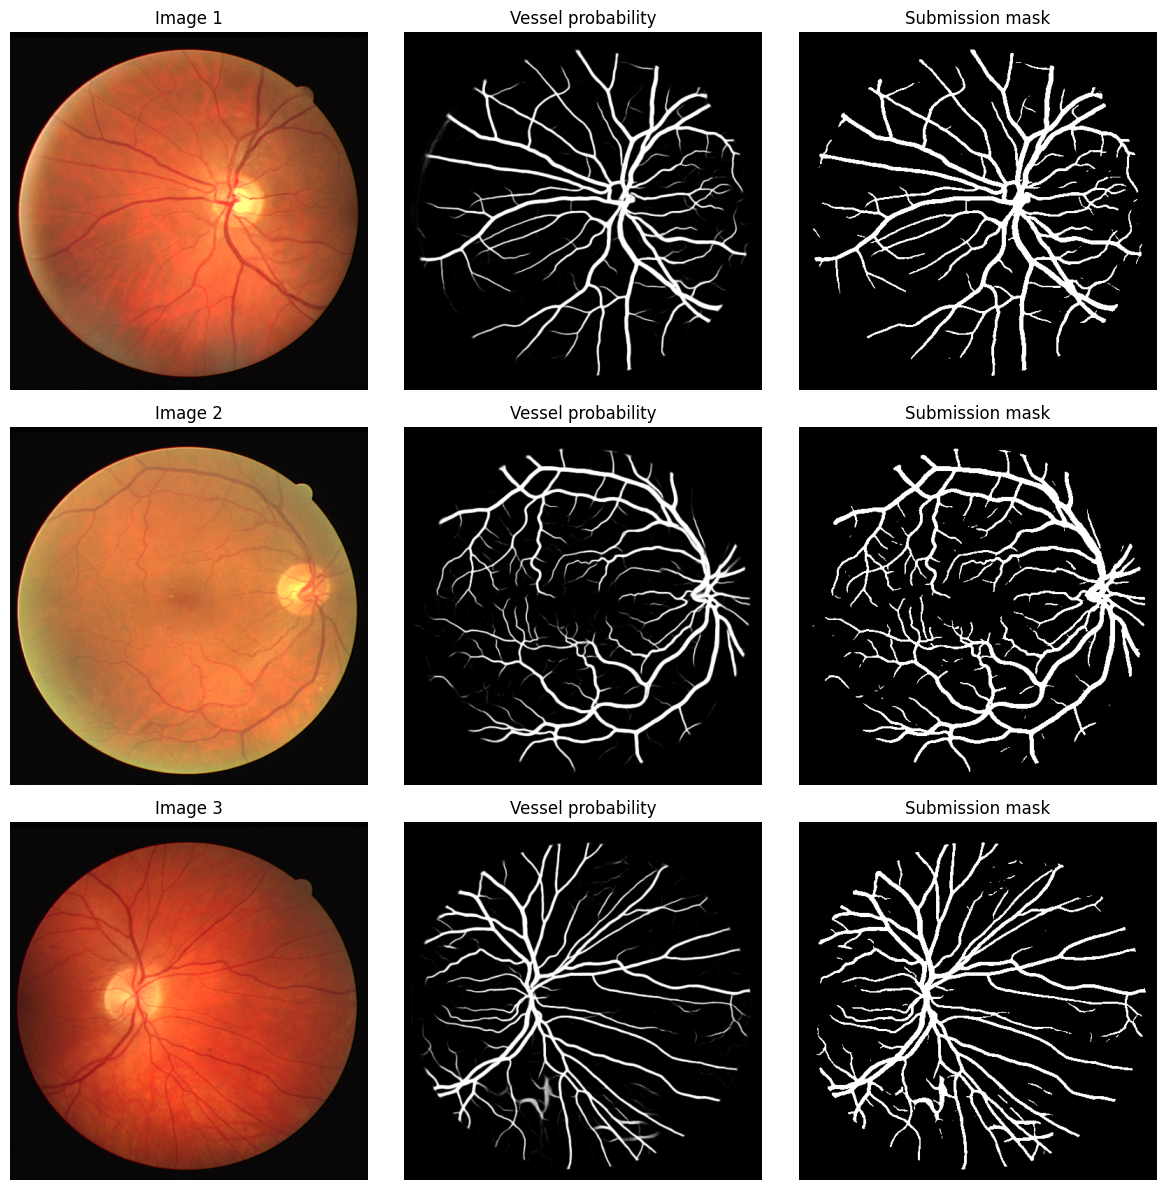

CSV: /kaggle/working/submission_run/submission.csv bytes: 818859
点击下面的 submission.csv 下载；浏览器决定保存目录。


/kaggle/working/submission_run/submission.csv

In [7]:
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

root = find_data_root(cfg.data_dir)
files = image_files(root / 'test/image')
saved = np.load(submission_path.parent / 'test_probabilities.npz')
preview_ids = saved['ids'][:3]
fig, axes = plt.subplots(len(preview_ids), 3, figsize=(12, 4 * len(preview_ids)), squeeze=False)
for row, name in enumerate(preview_ids):
    p = saved['probabilities'][row]
    with Image.open(files[str(name)]) as im:
        axes[row, 0].imshow(im.resize((512, 512)))
    axes[row, 1].imshow(p, cmap='gray', vmin=0, vmax=1)
    axes[row, 2].imshow(p >= metrics['threshold'], cmap='gray', vmin=0, vmax=1)
    for col, title in enumerate([f'Image {name}', 'Vessel probability', 'Submission mask']):
        axes[row, col].set_title(title)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

print('CSV:', submission_path, 'bytes:', submission_path.stat().st_size)
print('点击下面的 submission.csv 下载；浏览器决定保存目录。')
try:
    link_path = submission_path.relative_to(Path.cwd())
except ValueError:
    import shutil
    link_path = Path('submission_download.csv')
    shutil.copy2(submission_path, link_path)
display(FileLink(str(link_path)))
